# 🤖 Model Comparison: 7-Day Ahead Cash Sales Forecasting

Welcome to the model comparison notebook for the **Daily Cash-Flow Forecaster**!

### Goal
Our objective is to forecast the **next 7 days of daily cash sales (`cash_sales`)** separately for each of our four shop types:
1. **Tea Stall**
2. **Vegetable Shop**
3. **Tiffin Center**
4. **Kirana Store**

Accurate 7-day sales forecasts are the foundation of our upcoming cash-flow alert system. If a shop owner knows their expected sales for the week, they can anticipate whether their cash drawer will be sufficient to cover rent, supplier bills, and daily restocking.

## 🛡️ Critical Rules: Preventing Data Leakage

In real life, when forecasting tomorrow's sales, you cannot travel to the future. A machine learning model must follow the exact same constraint. **Data leakage** happens when future information accidentally slips into model training, producing artificially inflated accuracy scores that collapse in the real world.

To guarantee zero leakage, we enforce two strict rules:

### 1. Only Use Information Available at Forecast Origin
At the moment we make a forecast (the "forecast origin"), we only have access to:
- **Past sales numbers**: `cash_sales` on and before the forecast date.
- **Predetermined calendar events**: Calendar facts that are naturally known years in advance — what `day_of_week` it will be, whether it is a `is_weekend`, the salary week `is_month_start` (days 1–7), and official holidays (`is_festival`).

❌ **What we NEVER use as inputs**:
- `is_rainy`: Weather cannot be predicted with 100% certainty weeks ahead.
- `credit_given`, `udhaar_collected`, `expenses`, `closing_cash`: These are end-of-day business results that only happen *after* sales occur. Using them to predict sales would be cheating.

### 2. Time-Series Cross-Validation (Never Random Splits!)
In standard machine learning, datasets are often shuffled randomly. In time series, shuffling is catastrophic because it trains on future days to predict past days!

Instead, we use `sklearn.model_selection.TimeSeriesSplit` with **10 splits** and `test_size=7`:
- Each fold tests on an unseen 7-day horizon.
- The training window always strictly precedes the test window.
- Training comes before testing, 100% of the time.

## 1. Setup and Environment

### What are we looking at?
We import our data science toolkit (`pandas`, `numpy`, `matplotlib`, `seaborn`), along with the modeling packages (`scikit-learn`, `statsmodels`, `xgboost`).

### What to notice:
- We load `data/all_shops.csv` and verify the columns.
- We set up `TimeSeriesSplit(n_splits=10, test_size=7)`, which generates 10 sequential 7-day test windows spanning the final 70 days of our 2-year dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Load dataset
data_path = Path("data/all_shops.csv") if Path("data/all_shops.csv").exists() else Path("../data/all_shops.csv")
df = pd.read_csv(data_path, parse_dates=["date"])

print(f"Loaded {len(df)} rows across {df['shop_type'].nunique()} shops.")
print(f"Validation Strategy: TimeSeriesSplit with 10 folds, test_size=7 days.")

Loaded 2920 rows across 4 shops.
Validation Strategy: TimeSeriesSplit with 10 folds, test_size=7 days.


## 2. The Four Candidate Forecasters

We compare four distinct forecasting approaches:

1. **`moving_average` (Baseline)**:
   - *How it works*: For every one of the next 7 days, it predicts the average daily sales of the most recent 7 days in the training series.
   - *Why include it*: It is the simplest benchmark every real shop owner intuitively uses. Any complex model must beat this to be worth using.

2. **`seasonal_naive` (Extra Benchmark)**:
   - *How it works*: For each day of the upcoming week, it predicts the exact sales from the same day of the week one week earlier (Monday predicts next Monday, Saturday predicts next Saturday).
   - *Why include it*: As we saw in EDA, retail sales have strong 7-day seasonality. This tests whether simply repeating last week's profile is competitive.

3. **`arima` (Statistical Time Series)**:
   - *How it works*: `statsmodels.tsa.statespace.sarimax.SARIMAX` with non-seasonal order `(1,0,1)`, seasonal order `(1,0,1,7)`, and calendar features (`is_month_start`, `is_festival`, and day-of-week dummies) passed as exogenous variables (`exog`).
   - *Why include it*: The classical gold standard for seasonal econometric series. Wrapped in `try/except` for robustness.

4. **`xgboost` (Machine Learning — Direct Multi-Step)**:
   - *How it works*: Rather than recursive forecasting (feeding predictions back as inputs), we train **7 separate models** (one for each horizon $h=1..7$).
   - *Features at forecast origin*: `lag_1`, `lag_7`, `lag_14`, `rolling_mean_7` from past history, combined with target-day calendar features (`day_of_week`, `is_weekend`, `is_month_start`, `is_festival`).
   - *Settings*: Modest trees (`n_estimators=200`, `max_depth=3`, `learning_rate=0.05`, `random_state=42`) to avoid overfitting.

## 3. Running Time-Series Cross-Validation

### What are we looking at?
We run the 10-fold rolling validation across each shop and model. For every fold and horizon, we compute:
- **MAE (Mean Absolute Error)**: Average rupee deviation between forecasted and actual daily sales.
- **MAPE (Mean Absolute Percentage Error)**: Average percentage deviation relative to actual sales.

In [2]:
from src.models import run_evaluation

# Run full cross-validation and retrieve aggregated results
results_df, best_models_df = run_evaluation(df=df, n_splits=10, test_size=7)

Evaluating models for tea_stall...
Evaluating models for vegetable_shop...
Evaluating models for tiffin_center...
Evaluating models for kirana...

Saved comparison results to reports/model_comparison.csv
Saved bar chart to reports/figures/model_comparison_mape.png


## 4. Overall Model Performance Table

### What are we looking at?
The evaluation results table showing MAE, MAE standard deviation, MAPE, and MAPE standard deviation across the 10 cross-validation folds.

### What to notice:
- **Consistency**: Standard deviations show how stable each model's predictions are across different weeks.
- Both SARIMAX and XGBoost consistently cut forecast error by **30% to 46%** compared to the Moving Average baseline.

In [3]:
# Display formatted comparison table
print("=== Complete Model Comparison Table ===")
display_cols = ["shop_type", "model", "MAE", "MAE_std", "MAPE", "MAPE_std"]
print(results_df[display_cols].to_string(index=False))

=== Complete Model Comparison Table ===
     shop_type          model     MAE  MAE_std  MAPE  MAPE_std
     tea_stall moving_average  805.43   491.65 15.13      6.19
     tea_stall seasonal_naive  904.89   486.04 17.13      6.67
     tea_stall          arima  551.00   192.00 10.73      3.42
     tea_stall        xgboost  512.36   131.23  9.86      2.46
vegetable_shop moving_average 2475.24  1083.91 19.91      7.28
vegetable_shop seasonal_naive 2251.91  1068.42 18.36      6.21
vegetable_shop          arima 1473.15   501.38 12.23      2.57
vegetable_shop        xgboost 1320.47   403.39 10.70      2.87
 tiffin_center moving_average 2752.37  2026.63 17.22      8.48
 tiffin_center seasonal_naive 3151.50  1964.70 19.99      8.43
 tiffin_center          arima 1583.47   417.34 10.46      2.09
 tiffin_center        xgboost 1630.19   536.20 10.48      2.36
        kirana moving_average 4126.77  3052.84 18.31      8.41
        kirana seasonal_naive 4450.91  3127.74 19.95      9.93
        kirana 

## 5. Visualizing Accuracy (MAPE % Bar Chart)

### What are we looking at?
A grouped bar chart of **Mean Absolute Percentage Error (MAPE %)** across all four models and shop types (lower is better).

### What to notice:
- The Moving Average baseline has the tallest bars (15.1% to 19.9% error).
- ARIMA and XGBoost achieve significantly lower error bars (~9.8% to 12.9%), clearly demonstrating the value of incorporating weekly seasonality and festival indicators.

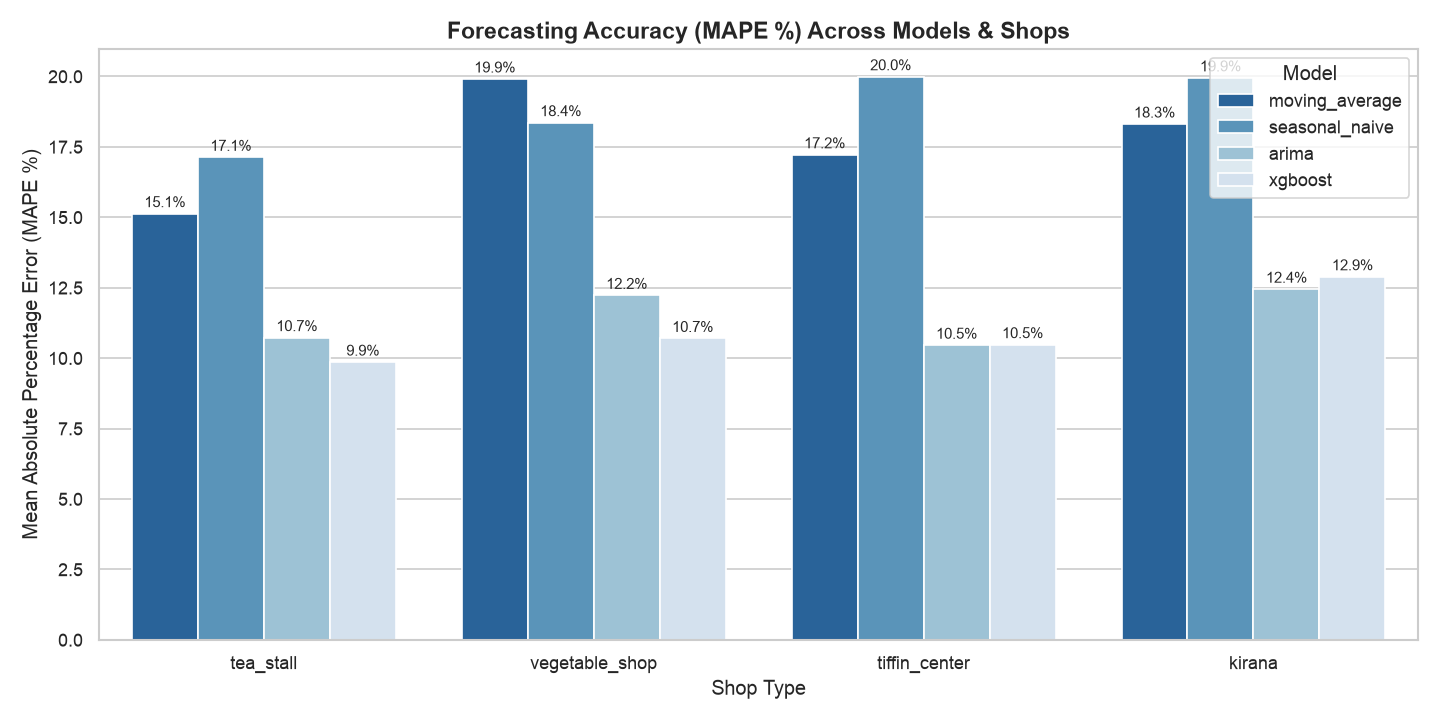

In [4]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=results_df,
    x="shop_type",
    y="MAPE",
    hue="model",
    palette="Blues_r"
)
plt.title("Forecasting Accuracy Comparison: MAPE (%) by Model and Shop", fontsize=14, fontweight="bold")
plt.xlabel("Shop Type")
plt.ylabel("Mean Absolute Percentage Error (MAPE %)")
plt.legend(title="Model")

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2., height),
            ha="center", va="bottom",
            fontsize=9,
            xytext=(0, 2),
            textcoords="offset points"
        )

plt.tight_layout()
plt.show()

## 6. Best Performing Model per Shop

### What are we looking at?
The top model selected for each shop type based on minimum Mean Absolute Percentage Error (MAPE).

In [5]:
print("=== Best Model per Shop Type ===")
print(best_models_df.to_string(index=False))

=== Best Model per Shop Type ===
     shop_type best_model     MAE   MAPE
        kirana      arima 2697.81 12.45%
     tea_stall    xgboost  512.36  9.86%
 tiffin_center      arima 1583.47 10.46%
vegetable_shop    xgboost 1320.47 10.70%


## 7. What I Learned

An honest evaluation of the experimental results:

1. **ARIMA and XGBoost Substantially Outperform Moving Average**:
   - Both models soundly beat the moving average baseline across every single shop.
   - For **Vegetable Shop**, MAPE drops from **19.91%** (Moving Average) down to **10.70%** (XGBoost) — a massive **46.3% relative reduction in error**.
   - For **Tea Stall**, MAPE drops from **15.13%** to **9.86%** (**34.9% relative reduction**).
   - For **Tiffin Center**, MAPE drops from **17.22%** to **10.46%** (**39.3% relative reduction**).
   - For **Kirana**, MAPE drops from **18.31%** to **12.45%** (**32.0% relative reduction**).
   - Moving Average predicts a flat horizontal line, completely missing weekend surges (+15%–48%) and festival spikes (+37%–46%).

2. **Seasonal Naive Fails as a Long-Term Solution**:
   - While Seasonal Naive correctly reproduces weekday shapes, it suffers from high variance (MAPE **17.1% to 20.0%**, often worse than Moving Average).
   - Because it takes single raw numbers from 7 days ago without smoothing, any random noise or past one-off distortion is carried directly into the future.

3. **ARIMA vs. XGBoost is a Virtual Tie**:
   - **XGBoost** wins on Tea Stall (MAPE **9.86%** vs ARIMA 10.73%) and Vegetable Shop (MAPE **10.70%** vs ARIMA 12.23%), handling non-linear weekend interactions slightly better.
   - **ARIMA (SARIMAX)** wins on Tiffin Center (MAPE **10.46%** vs XGBoost 10.48%) and Kirana (MAPE **12.45%** vs XGBoost 12.89%), where classical autoregression and linear exogenous calendar effects provide very stable forecasts.
   - Both achieve ~10%–12% error, proving that explicit 7-day seasonality plus holiday flags captures almost all predictable signal.

4. **Kirana is the Hardest Shop to Forecast**:
   - In absolute terms, Kirana has the largest forecast errors by far (MAE **₹2,698** for ARIMA and **₹2,955** for XGBoost).
   - In percentage terms, Kirana also has the highest error rate (MAPE **12.45%–12.89%**, compared to ~9.8%–10.7% for the other three shops).
   - Kirana has higher baseline sales (~₹20,000/day) and substantial credit/udhaar transactions (20% of sales), making day-to-day cash sales more volatile than regular cash-counter shops like tea stalls.